# 01 · 注意力与多头机制

读到“那只动物太累了，所以它停了下来”，你很自然地把“它”和“动物”联系起来。计算机拿到的却是一排数字：怎样让一个词找到其他词里的有用信息？

这一篇就拆开这个过程。我们用 **I love AI** 三个词，一步步算出它们怎样交换信息：先准备词向量，再匹配、分配权重、汇总内容，最后让多个注意力头并行工作。

## 从这里开始

在 `transformer` 目录运行 `uv sync --python 3.11.15`、`uv run jupyter lab`；VS Code 选择 `transformer/.venv/bin/python`。从第一格顺序运行，本篇使用小矩阵做数值演示。

整个主题有四站：
1. **本篇**：看见注意力内部的信息流动。
2. [位置编码与网络层](02_位置编码与网络层.ipynb)：把注意力装进完整模型。
3. [逆序任务与自回归生成](03_逆序任务与自回归生成.ipynb)：教模型把一串数字倒着写。
4. [德英翻译实战](04_德英翻译实战.ipynb)：换上真正的句子。

环境配置详情见[仓库入口](../README.md)。

In [1]:
"""
Self-Attention 完整执行流程示例
通过一个具体例子，逐步展示数据如何流动：输入 → Q,K,V → 注意力分数 → 输出
"""

import torch
import torch.nn as nn
import math
import numpy as np

print("=" * 80)
print("🎯 Self-Attention 完整执行流程示例")
print("=" * 80)


import matplotlib.pyplot as plt


🎯 Self-Attention 完整执行流程示例


## 预备 A · 张量：给数据安排座位

把数据想成图书馆里的书：一本书的价格是**标量**，一排价格是**向量**，多排价格组成**矩阵**。再加一层“楼层”，就有了三维张量。

词向量也这样摆放。`(B, L, D)` 的三个数字依次表示：**几句话、每句几个位置、每个位置几个特征**。例如 `(2, 3, 4)`，就是两句话，每句三个词，每个词用四个数表示。

运行下一格，看看形状怎样随数据的层数变化。`batch_sentences[0, 0]` 取出的是第一句话中第一个词的整条向量。

In [ ]:
scalar = torch.tensor(29.9)
vector = torch.tensor([29.9, 35.0, 42.5])
matrix = torch.arange(6).reshape(2, 3)
batch_sentences = torch.zeros(2, 3, 4)
for name, value in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("sentences", batch_sentences)]:
    print(name, tuple(value.shape), "dimensions:", value.ndim)
print("First token:", batch_sentences[0, 0])

## 预备 B · 矩阵乘法：一张配方，换一种读法

配方写着“2 个鸡蛋、100 克面粉、50 克糖”，你想知道其中有多少蛋白质和碳水。只要列出每种原料的营养系数，就能把一张**原料表**变成一张**营养表**。

这就是矩阵乘法要做的事：输入数据 × 转换规则 = 新的表示。下面用一组简化的营养系数，算出 `[22, 125]`。

对词向量也是一样：`(B,L,D) @ (D,O) → (B,L,O)`。每个词还是坐在原来的位置，描述它的数字从 D 个变成 O 个。后面生成 Q、K、V，用的正是这种转换。

代码中的 `nn.Linear(D,O)` 会把权重存成 `(O,D)`，计算时乘其转置，再加偏置。

In [ ]:
recipe = torch.tensor([2.0, 100.0, 50.0])
nutrition_rules = torch.tensor([[6.0, 0.1, 0.0], [0.0, 0.75, 1.0]])
print("Nutrition:", nutrition_rules @ recipe)
feature_table = torch.ones(2, 3, 4)
projection = torch.arange(32, dtype=torch.float32).reshape(4, 8) / 32
print("Feature transformation:", feature_table.shape, "->", (feature_table @ projection).shape)

## 预备 C · Embedding：凭编号查一行向量

给每个 token 一个编号，再准备一张向量表。编号是 2，就取第 2 行；编号是 5，就取第 5 行。**Embedding 的第一步，就是查表。**

下一格输入 `[2, 5, 2]`。先猜猜：哪两行输出会一样？

这张表最初随机填写，之后通过训练修改。训练会让向量逐渐承载任务需要的信息；这一格先看清“编号 → 向量”的对应关系。

In [ ]:
with torch.random.fork_rng():
    torch.manual_seed(7)
    lookup = nn.Embedding(10, 4)
    token_ids = torch.tensor([2, 5, 2])
    word_vectors = lookup(token_ids)
print("IDs:", token_ids, "vectors:", word_vectors)
print("Same ID, same vector:", word_vectors[0], word_vectors[2])
print("Random-vector cosine:", torch.cosine_similarity(word_vectors[0], word_vectors[1], dim=0).item())

### 先看一眼完整路线

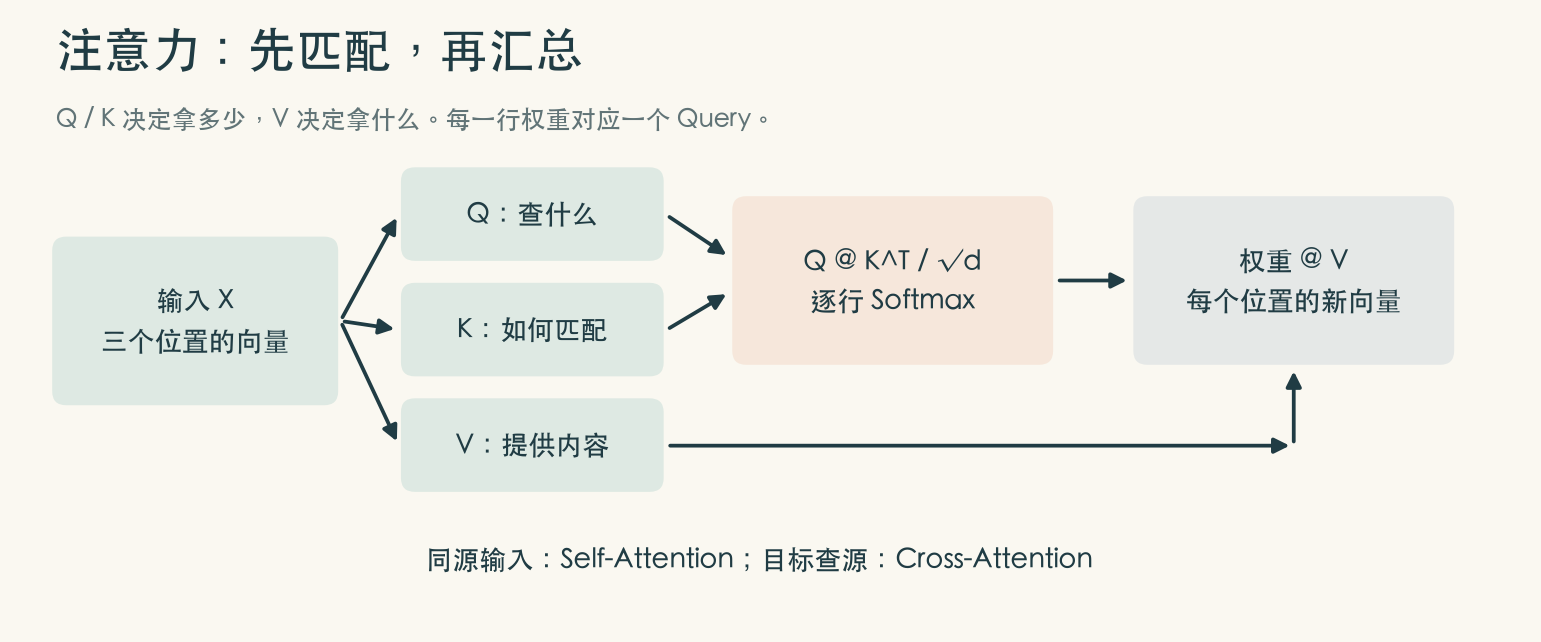

顺着箭头读：Q 去找 K，得到一张匹配表；Softmax 把分数变成份额；最后按份额取出 V 中的内容。接下来把这条路线一格格算出来。

## 1. 把 I、love、AI 摆成一张表

每个词占一行，每行四个数。于是三个词组成一个 `(3, 4)` 矩阵 X：第一维数词，第二维数特征。

下面直接给出这三个词的小向量。先记住它们的座位，后面的 Q、K、V 和输出都会沿用这个顺序。

In [ ]:
print("\n【步骤 0】准备输入数据")
print("-" * 80)

# 句子："I love AI"（3个词）
sentence = ["I", "love", "AI"]
seq_len = 3  # 序列长度
d_model = 4  # 每个词的向量维度（简化为4维便于理解）

print(f"句子: {sentence}")
print(f"序列长度: {seq_len}")
print(f"词向量维度: {d_model}")

# 模拟词嵌入：每个词都用一个4维向量表示
# 在实际应用中，这些向量是通过Embedding层学习得到的
X = torch.tensor([
    [1.0, 0.0, 0.5, 0.2],  # "I" 的向量
    [0.0, 1.0, 0.3, 0.8],  # "love" 的向量
    [0.5, 0.5, 1.0, 0.1],  # "AI" 的向量
], dtype=torch.float32)

print(f"\n输入矩阵 X 的形状: {X.shape}  # [序列长度, 词向量维度]")
print("输入矩阵 X (每行是一个词的向量):")
print(X)
print("\n解释：")
print(f"  X[0] = {X[0].tolist()} ← 'I' 的向量")
print(f"  X[1] = {X[1].tolist()} ← 'love' 的向量")
print(f"  X[2] = {X[2].tolist()} ← 'AI' 的向量")




现在有了三行输入：`I`、`love`、`AI`。如果再加一个词，就多一行；如果给每个词更丰富的表示，就增加列数。

## 2. 每个词带上三张卡片：Q、K、V

把一句话想成一次小组讨论。每个词都带着三张卡片：

- **Q，问题卡**：我现在想找什么信息？
- **K，索引卡**：别人可以通过什么线索找到我？
- **V，内容卡**：如果有人关注我，我能提供什么？

同一份词向量分别乘上三套权重，就得到三张不同的卡片。下面先准备这三套转换规则：`W_q`、`W_k`、`W_v`。

这次所有卡片来自同一句话，叫 **Self-Attention（自注意力）**。翻译时，译文前缀也可以带着 Q 去查询原文的 K/V，那就是 **Cross-Attention（交叉注意力）**。

In [ ]:
print("\n\n【步骤 1】创建 Q, K, V 投影矩阵")
print("-" * 80)

d_k = d_model  # Query和Key的维度（这里简化为和d_model相同）
d_v = d_model  # Value的维度

print("💡 为什么需要投影矩阵？")
print("   虽然Q, K, V都来自同一个输入X，但我们希望它们在不同的")
print("   '表示空间'中学习，就像从不同角度观察同一个事物。")
print()

# 创建权重矩阵（随机初始化，实际训练中会学习）
torch.manual_seed(42)  # 固定随机种子，保证结果可复现

W_q = torch.randn(d_model, d_k) * 0.5  # Query权重矩阵
W_k = torch.randn(d_model, d_k) * 0.5  # Key权重矩阵  
W_v = torch.randn(d_model, d_v) * 0.5  # Value权重矩阵

print(f"W_q (Query权重) 形状: {W_q.shape}  # [d_model, d_k] = [{d_model}, {d_k}]")
print(f"W_k (Key权重) 形状:   {W_k.shape}  # [d_model, d_k] = [{d_model}, {d_k}]")
print(f"W_v (Value权重) 形状: {W_v.shape}  # [d_model, d_v] = [{d_model}, {d_v}]")

print("\nW_q 矩阵内容:")
print(W_q)




三套权重都接收四维词向量。它们各自保存参数，训练时分别调整：匹配线索和待汇总内容因此能学出不同的表示。

## 3. 把卡片写出来

现在执行三次矩阵乘法：

$$Q=XW_q,\qquad K=XW_k,\qquad V=XW_v.$$

先看 `love` 对应的第二行：它会得到自己的 Q、K、V。再看另外两行，每个词也都拥有同样的三种角色。

Q 和 K 要逐项相乘，所以它们的最后一维相同；V 的宽度决定待汇总内容有多少个特征。

In [ ]:
print("\n\n【步骤 2】通过矩阵乘法计算 Q, K, V")
print("-" * 80)

Q = torch.matmul(X, W_q)  # [seq_len, d_model] @ [d_model, d_k] = [seq_len, d_k]
K = torch.matmul(X, W_k)  # [seq_len, d_model] @ [d_model, d_k] = [seq_len, d_k]
V = torch.matmul(X, W_v)  # [seq_len, d_model] @ [d_model, d_v] = [seq_len, d_v]

print(f"Q (Query矩阵) 形状: {Q.shape}  # [seq_len, d_k] = [{seq_len}, {d_k}]")
print("Q 矩阵内容 (每行是一个词的Query向量):")
print(Q)
print(f"\n解释：Q[0] = {Q[0].tolist()[:2]}... 是'I'的Query向量")
print(f"     Q[1] = {Q[1].tolist()[:2]}... 是'love'的Query向量")
print(f"     Q[2] = {Q[2].tolist()[:2]}... 是'AI'的Query向量")

print(f"\n\nK (Key矩阵) 形状: {K.shape}  # [seq_len, d_k] = [{seq_len}, {d_k}]")
print("K 矩阵内容 (每行是一个词的Key向量):")
print(K)

print(f"\n\nV (Value矩阵) 形状: {V.shape}  # [seq_len, d_v] = [{seq_len}, {d_v}]")
print("V 矩阵内容 (每行是一个词的Value向量):")
print(V)

print("\n💡 理解Q, K, V的角色：")
print("   - Query(Q): '我在寻找什么信息？' (查询者)")
print("   - Key(K):   '我能提供什么信息？' (被查询者的标识)")
print("   - Value(V): '这是我要传递的具体信息' (实际内容)")




沿着同一个行号，就能追踪同一个词的三张卡片。例如 `Q[1]`、`K[1]`、`V[1]` 都属于 `love`。

## 4. 用点积问一句：我们匹配吗？

Q 拿着一张问题卡，和每张 K 逐项相乘，再把结果加起来。方向越一致、幅度越大，点积通常也越大：

$$q^Tk=\|q\|\|k\|\cos\theta.$$

一次 `Q @ K.T` 就能让所有词互相打分。接着除以 $\sqrt{d_k}$，相当于给分数调好音量：维数增加时，让数值幅度保持在更容易处理的尺度。

<details>
<summary>为什么恰好除以平方根？</summary>

假设 q、k 的各分量相互独立，均值为 0、方差为 1。d_k 项乘积相加后，点积方差为 d_k；除以 $\sqrt{d_k}$ 后，方差变为 1。这解释了初始化时的常用缩放方式。

</details>

In [ ]:
print("\n\n【步骤 3】计算注意力分数（Query和Key的相似度）")
print("-" * 80)

# 点积：Q @ K^T
scores = torch.matmul(Q, K.transpose(0, 1))  # [seq_len, d_k] @ [d_k, seq_len] = [seq_len, seq_len]

print(f"分数矩阵 (QK^T) 形状: {scores.shape}  # [seq_len, seq_len] = [{seq_len}, {seq_len}]")
print("未缩放的分数矩阵:")
print(scores)
print("\n🔍 矩阵含义（每个位置表示一个词对另一个词的相似度）:")
print(f"              {'I':>8}  {'love':>8}  {'AI':>8}")
print(f"  I     {scores[0, 0]:>8.3f}  {scores[0, 1]:>8.3f}  {scores[0, 2]:>8.3f}  ← 'I'对所有词的分数")
print(f"  love  {scores[1, 0]:>8.3f}  {scores[1, 1]:>8.3f}  {scores[1, 2]:>8.3f}  ← 'love'对所有词的分数")
print(f"  AI    {scores[2, 0]:>8.3f}  {scores[2, 1]:>8.3f}  {scores[2, 2]:>8.3f}  ← 'AI'对所有词的分数")

# 缩放（除以sqrt(d_k)）
scaled_scores = scores / math.sqrt(d_k)

print(f"\n缩放后的分数 (除以√{d_k} ≈ {math.sqrt(d_k):.2f}):")
print(scaled_scores)
print("\n💡 为什么要缩放？")
print("   防止维度增大时，点积值过大导致softmax梯度消失")




得到的是一张 `(3, 3)` 的打分表：三位提问者 × 三位信息提供者。第二行依次记录 `love` 对 `I`、`love`、`AI` 的匹配分数。

### 换一个音量，权重会怎样？

下面给同一组 Q/K 使用三种打分规则：原始点积、除以 $\sqrt{d_k}$ 的点积、单位化后的余弦相似度。

看每一行最后打印的 `weights`：分数间的差距拉大后，最高分拿到的份额会更集中。再看不同维数下的方差，观察缩放怎样抵消维数增长带来的数值变化。

还有一种常见选择是**加性注意力**：用小网络 $v^T\tanh(W_q q+W_k k)$ 学习打分规则。这里先把缩放点积这条路走通。

In [ ]:
with torch.random.fork_rng():
    torch.manual_seed(12)
    similarity_q = torch.randn(1, 64)
    similarity_k = torch.randn(5, 64)
raw_scores = similarity_q @ similarity_k.T
cosine_scores = torch.nn.functional.normalize(similarity_q, dim=-1) @ torch.nn.functional.normalize(similarity_k, dim=-1).T
for name, values in [("dot", raw_scores), ("scaled", raw_scores / math.sqrt(64)), ("cosine", cosine_scores)]:
    print(name, "scores:", values, "weights:", values.softmax(dim=-1))
with torch.random.fork_rng():
    torch.manual_seed(13)
    for dim in [4, 16, 64, 256]:
        samples_q, samples_k = torch.randn(2000, dim), torch.randn(2000, dim)
        dots = (samples_q * samples_k).sum(dim=-1)
        print(f"D={dim:3}: raw variance={dots.var(unbiased=False):.2f}, scaled variance={(dots / math.sqrt(dim)).var(unbiased=False):.2f}")

## 5. Softmax：把分数换成“各取多少”

假设 `love` 对三个词的分数是 `[2, 1, 0]`。Softmax 会把它们变成约 `[0.665, 0.245, 0.090]`：三份加起来为 1，最高分拿到最多份额。

$$a_j=\frac{e^{s_j}}{\sum_k e^{s_k}}.$$

每个 Query 都有自己的一份总预算，所以我们**逐行**计算 Softmax，也就是沿最后一维 `dim=-1` 计算。下一格使用刚才实际算出的分数。

In [ ]:
print("\n\n【步骤 4】应用 Softmax 将分数转换为概率分布")
print("-" * 80)

attention_weights = torch.softmax(scaled_scores, dim=-1)  # 在最后一维上做softmax

print(f"注意力权重矩阵形状: {attention_weights.shape}  # [{seq_len}, {seq_len}]")
print("注意力权重矩阵 (每行和为1):")
print(attention_weights)

print("\n🔍 注意力权重解读（概率分布）:")
print(f"              {'I':>8}  {'love':>8}  {'AI':>8}  {'行和':>8}")
row_sums = attention_weights.sum(dim=-1)
for i, word in enumerate(sentence):
    weights_str = "  ".join([f"{attention_weights[i, j]:>8.3f}" for j in range(seq_len)])
    print(f"  {word:<4}  {weights_str}  {row_sums[i]:>8.3f}")

print("\n💡 解释：")
print(f"   'I' 最关注 '{sentence[int(torch.argmax(attention_weights[0]).item())]}' (权重={attention_weights[0].max():.3f})")
print(f"   'love' 最关注 '{sentence[int(torch.argmax(attention_weights[1]).item())]}' (权重={attention_weights[1].max():.3f})")
print(f"   'AI' 最关注 '{sentence[int(torch.argmax(attention_weights[2]).item())]}' (权重={attention_weights[2].max():.3f})")




横着读一行：哪个词拿到的份额最多？再把这一行相加，看看是否为 1。这样，一张匹配分数表就变成了配比表。

## 6. 按配比，调出新的词向量

权重已经定好了，现在轮到 V 提供内容。假设某一行权重是 `[0.6, 0.3, 0.1]`，这一行输出就是：

$$0.6V_0+0.3V_1+0.1V_2.$$

像按配方调一杯饮料，每种原料取多少由权重决定。对所有行一起做，就是 `attention_weights @ V`。

In [ ]:
print("\n\n【步骤 5】用注意力权重对Value进行加权求和")
print("-" * 80)

output = torch.matmul(attention_weights, V)  # [seq_len, seq_len] @ [seq_len, d_v] = [seq_len, d_v]

print(f"输出矩阵形状: {output.shape}  # [seq_len, d_v] = [{seq_len}, {d_v}]")
print("输出矩阵内容:")
print(output)

print("\n🔍 详细计算过程（以'love'为例）:")
print(f"\n   'love'的输出 = 加权求和所有词的Value:")
print(f"   output[1] = {attention_weights[1, 0]:.3f} * V[0]  (权重 × 'I'的value)")
print(f"             + {attention_weights[1, 1]:.3f} * V[1]  (权重 × 'love'的value)")
print(f"             + {attention_weights[1, 2]:.3f} * V[2]  (权重 × 'AI'的value)")
print(f"\n   计算结果:")

manual_calc = (attention_weights[1, 0] * V[0] + 
               attention_weights[1, 1] * V[1] + 
               attention_weights[1, 2] * V[2])
print(f"   手动计算: {manual_calc.tolist()}")
print(f"   矩阵计算: {output[1].tolist()}")
print(f"   验证一致: {torch.allclose(manual_calc, output[1])}")




每个 Query 收到一条新向量，它的宽度和 V 一样。可以记成一句话：**权重管“取多少”，V 管“取什么”。**

## 7. 交换信息之后，三个词变成了什么？

输入中每个词拿着自己的向量；经过注意力后，每个词都收到一份按自身权重调配的内容。

下一格把输入和输出并排打印。挑 `love` 这一行，回头找到它的权重，就能沿着“它关注了谁 → 汇总了哪些 V”解释计算过程。

In [ ]:
print("\n\n【步骤 6】对比输入和输出，理解Self-Attention的作用")
print("-" * 80)

print("对比每个词的输入和输出向量：\n")

for i, word in enumerate(sentence):
    print(f"词: '{word}'")
    print(f"  输入向量:  {X[i].tolist()}")
    print(f"  输出向量:  {output[i].tolist()}")
    
    # 计算变化
    diff = output[i] - X[i]
    print(f"  变化:      {diff.tolist()}")
    print(f"  变化幅度:  {torch.norm(diff).item():.4f}")
    print()

print("💡 Self-Attention做了什么？")
print("   1. 每个词的输出 = 融合了其他相关词的信息")
print("   2. 注意力权重决定了融合的比例")
print("   3. 输出向量包含了更丰富的上下文信息")




输出仍有三行，一词一行。不同词使用不同的配比，因此即使它们读取的是同一组 V，收到的结果也可以不同。

## 8. 把整条路线连起来

现在可以从 X 一路追到输出了：先给每个词生成 Q/K/V，再让 Q 和 K 匹配，最后按权重汇总 V。

留意其中两个动作：`X @ W` 在加工**每个词内部的特征**；注意力权重乘 V 在**词与词之间传递内容**。

In [ ]:
print("\n\n【步骤 7】完整数据流总结")
print("=" * 80)

print("""
完整的Self-Attention计算流程：

输入: X                     形状: [3, 4]   (3个词，每词4维)
  ↓
投影变换:
  Q = X @ W_q              形状: [3, 4]   (Query矩阵)
  K = X @ W_k              形状: [3, 4]   (Key矩阵)
  V = X @ W_v              形状: [3, 4]   (Value矩阵)
  ↓
计算相似度:
  scores = Q @ K^T         形状: [3, 3]   (每个词对其他词的分数)
  ↓
缩放:
  scaled_scores = scores / √d_k
  ↓
归一化:
  attention = softmax(scaled_scores)  形状: [3, 3]   (注意力权重，每行和为1)
  ↓
加权求和:
  output = attention @ V   形状: [3, 4]   (融合上下文后的输出)

关键点：
✓ Q, K, V 都来自同一个输入 X（这就是"Self"的含义）
✓ 注意力权重矩阵是方阵 [seq_len, seq_len]
✓ 每个词都可以关注包括自己在内的所有词
✓ 输出维度和输入维度相同 [seq_len, d_model]
""")




给这五步各起一个动词：**投影 → 匹配 → 缩放 → 分配 → 汇总**。后面的多头版本，仍然沿着这条路线走。

## 9. 怎样读懂一张注意力表？

把行当作“谁在问”，列当作“向谁取信息”。想知道 `love` 从哪里汇总内容，就横着读它对应的那一行。

下一格把权重排成文字表格。先找每行最大的数，再看不同词的配比是否相同。

In [ ]:
print("\n\n【步骤 8】注意力热力图（文本版）")
print("-" * 80)

print("\n注意力权重可视化（数字越大，关注度越高）:")
print(f"\n{'':>8}", end="")
for word in sentence:
    print(f"{word:>8}", end="")
print()

for i, word in enumerate(sentence):
    print(f"{word:>8}", end="")
    for j in range(seq_len):
        weight = attention_weights[i, j].item()
        # 用符号表示权重大小
        if weight > 0.5:
            symbol = "████"
        elif weight > 0.3:
            symbol = "███ "
        elif weight > 0.2:
            symbol = "██  "
        else:
            symbol = "█   "
        print(f"{symbol}", end="")
    print(f"  (最关注: {sentence[int(torch.argmax(attention_weights[i]).item())]})")


print("\n" + "=" * 80)
print("✅ Self-Attention 执行流程示例完成！")
print("=" * 80)

print("\n🎓 核心要点回顾:")
print("1. Self-Attention让每个词能看到序列中的所有词（包括自己）")
print("2. Q, K, V通过不同的投影矩阵从同一输入生成")
print("3. 注意力权重 = softmax(QK^T/√d_k) 表示词之间的相关性")
print("4. 输出 = 注意力权重加权求和Value，融合上下文信息")
print("5. 输入和输出形状相同，但输出包含了更丰富的语义")

这张表是一次计算中的配比记录。把它和 V 放在一起，就能还原每一行输出怎样算出来。

## 10. 多头：让几张关注表同时工作

一张表可以偏向某个位置，另一张表可以偏向另一个位置。多头注意力让这些配比同时存在，最后再把得到的内容合起来。

像请几位读者分别做阅读笔记：他们各有一套投影参数，关注方式随训练形成。下面用 `d_model=4`、`num_heads=2`，把总宽度分成两个宽度为 2 的头。

```text
先投影       (B, L, 4)
拆成两个头   (B, L, 2, 2)
把头移到前面 (B, 2, L, 2)
每头各算注意力，再拼回 (B, L, 4)
最后经过输出投影，融合两份内容
```

`transpose(1, 2)` 把头挪到批次旁边，让矩阵乘法并行处理它们；拼回去时，`contiguous()` 先整理内存，再用 `view` 合并维度。

<details>
<summary>换成一般维度，该怎样读形状？</summary>

每头宽度是 D/H。Q/K 的匹配表为 `(B,H,Lq,Lk)`，汇总 V 后为 `(B,H,Lq,D/H)`，合并后回到 `(B,Lq,D)`。交叉注意力中的 Lq 和 Lk 可以不同。

固定 D 时，注意力乘加的主项约为 $L^2D$；头数 H 还会影响注意力表的存储和计算调度。

</details>

In [ ]:
torch.manual_seed(42)
batch_x = X.unsqueeze(0)
num_heads = 2
head_dim = d_model // num_heads
q_proj = nn.Linear(d_model, d_model, bias=False)
k_proj = nn.Linear(d_model, d_model, bias=False)
v_proj = nn.Linear(d_model, d_model, bias=False)
out_proj = nn.Linear(d_model, d_model, bias=False)

def split_heads(values):
    return values.reshape(1, len(sentence), num_heads, head_dim).transpose(1, 2)

with torch.no_grad():
    q_heads = split_heads(q_proj(batch_x))
    k_heads = split_heads(k_proj(batch_x))
    v_heads = split_heads(v_proj(batch_x))
    head_scores = q_heads @ k_heads.transpose(-2, -1) / math.sqrt(head_dim)
    head_weights = torch.softmax(head_scores, dim=-1)
    head_context = head_weights @ v_heads
    merged = head_context.transpose(1, 2).contiguous().reshape(1, len(sentence), d_model)
    multi_head_output = out_proj(merged)

print("Input:", batch_x.shape)
print("Per-head Q:", q_heads.shape)
print("Per-head attention:", head_weights.shape)
print("Merged output:", multi_head_output.shape)

fig, axes = plt.subplots(1, num_heads, figsize=(9, 3))
for head, ax in enumerate(axes):
    ax.imshow(head_weights[0, head].numpy(), vmin=0, vmax=1, cmap="YlGnBu")
    ax.set_xticks(range(len(sentence)), sentence)
    ax.set_yticks(range(len(sentence)), sentence)
    ax.set_title(f"Head {head + 1}")
    ax.set_xlabel("Key")
    ax.set_ylabel("Query")
plt.tight_layout()
plt.show()

比较两个头的权重：这格使用两组随机投影，先让你看到“各自匹配、各自汇总”的结构。最后拼接时，两份宽度为 2 的结果又合成了宽度为 4 的向量。

## 11. 把这条流程装进一个模块

前面逐句计算的过程，现在放进 `SelfAttention.forward`。以后只需传入 x，就能拿到输出和注意力权重。

读这段类定义时，可以在心里给代码贴上刚才的五个动词。这里还加了两个开关：**mask 控制可见位置，Dropout 在训练时随机丢弃部分注意力权重**。下面的演示用 `eval()` 关闭 Dropout，方便直接读权重。

In [ ]:
class SelfAttention(nn.Module):
    """
    Self-Attention模块（Transformer论文中的Scaled Dot-Product Attention）

    输入形状: [batch_size, seq_len, d_model]
    输出形状: [batch_size, seq_len, d_model]
    """

    def __init__(self, d_model, d_k=None, d_v=None, dropout=0.1):
        """
        初始化参数：
        - d_model: 输入嵌入维度
        - d_k: Query/Key维度 (默认 = d_model，这里使用单头)
        - d_v: Value维度
        - dropout: Dropout率
        """
        super().__init__()

        self.d_model = d_model
        self.d_k = d_k if d_k is not None else d_model
        self.d_v = d_v if d_v is not None else d_model

        # Q, K, V 线性投影层
        self.w_q = nn.Linear(d_model, self.d_k)
        self.w_k = nn.Linear(d_model, self.d_k)
        self.w_v = nn.Linear(d_model, self.d_v)

        # 输出投影层（融合注意力后的线性变换）
        self.w_o = nn.Linear(self.d_v, d_model)

        # Dropout层
        self.dropout = nn.Dropout(dropout)

        print(f"✅ SelfAttention初始化:")
        print(f"   d_model={d_model}, d_k={self.d_k}, d_v={self.d_v}")
        print(f"   投影层: w_q({d_model}->{self.d_k}), w_k({d_model}->{self.d_k}), w_v({d_model}->{self.d_v}), w_o({self.d_v}->{d_model})")

    def forward(self, x, mask=None):
        """
        前向传播

        Args:
            x: 输入 [batch_size, seq_len, d_model]
            mask: 可选注意力掩码 [batch_size, seq_len, seq_len]，用于Decoder遮蔽未来信息

        Returns:
            output: [batch_size, seq_len, d_model]
            attention_weights: [batch_size, seq_len, seq_len] (调试用)
        """
        batch_size, seq_len, d_model = x.shape

        print(f"\n🔄 前向传播输入形状: {x.shape}")

        # 1. 生成 Q, K, V
        Q = self.w_q(x)  # [batch, seq, d_k]
        K = self.w_k(x)  # [batch, seq, d_k]
        V = self.w_v(x)  # [batch, seq, d_v]

        print(f"   Q形状: {Q.shape}, K形状: {K.shape}, V形状: {V.shape}")

        # 2. 计算注意力分数
        # Q @ K.transpose(-2, -1) → [batch, seq, seq]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        print(f"   原始分数形状: {scores.shape}")

        # 3. 应用掩码（如果提供）
        if mask is not None:
            # 布尔 mask 中 True 可见、False 屏蔽；不是加性 -inf 掩码
            scores = scores.masked_fill(mask == 0, -1e9)
            print(f"   应用mask后分数形状: {scores.shape}")

        # 4. Softmax得到注意力权重
        attention_weights = torch.nn.functional.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)
        print(f"   注意力权重形状: {attention_weights.shape}")

        # 5. 加权求和
        context = torch.matmul(attention_weights, V)  # [batch, seq, d_v]

        # 6. 输出投影
        output = self.w_o(context)  # [batch, seq, d_model]

        print(f"   输出形状: {output.shape}")

        return output, attention_weights

### 加上眼罩，再看一次权重

让三个词按顺序发言：第一位只读到自己，第二位读到前两位，第三位读到全部。

下一格用下三角 mask 实现这条规则。观察权重表的右上角：被遮住的位置权重变成 0，每一行把份额分给仍然可见的词。

In [ ]:
single_attention = SelfAttention(d_model=4, dropout=0.0).eval()
visible_prefix = torch.ones(3, 3, dtype=torch.bool).tril()[None]
with torch.no_grad():
    single_output, single_weights = single_attention(X.unsqueeze(0), mask=visible_prefix)
print("Output:", single_output.shape)
print("Allowed-prefix weights:", single_weights[0])

## 带走三个问题

<details>
<summary>Q、K、V 分别做了什么？</summary>

Q 提出查询，K 提供匹配线索，V 提供被汇总的内容。Q/K 算出配比，配比乘 V 得到新向量。

</details>

<details>
<summary>为什么沿一行做 Softmax？</summary>

一行属于一个 Query，它要在所有 Key 之间分配总和为 1 的权重。

</details>

<details>
<summary>两个头拼接后，为什么宽度仍是 4？</summary>

我们先把总宽度 4 分成两份，每份宽度 2；各自计算后再拼回来，得到 2 + 2 = 4。

</details>

可以改一个词的输入向量，再观察它怎样影响各行权重和输出。接下来去[位置编码与网络层](02_位置编码与网络层.ipynb)，给这些会交换信息的词加上顺序感。